# Avaliação do Agente — Assistente do Funcionário ASA · SISA

**Entrega 2 — Avaliação, explicabilidade e serviço de inferência**

O Agente ajuda o funcionário da Central de Atendimento ao Aluno a **entender uma solicitação de aluno**: resume o pedido, identifica o problema e o requerimento do catálogo oficial, sugere a prioridade e os próximos passos — e **se abstém** quando não há informação suficiente.

Este notebook avalia o **sistema real**: sobe a API FastAPI do backend (`server.py`) e chama o endpoint `POST /api/staff/requirement-assistant`, o mesmo que o aplicativo usa.

### Como executar no Google Colab
1. Clique no ícone de chave (🔑 *Secrets*) e verifique se a chave groq está configurada e ativado o acesso ao notebook. Caso não esteja, crie `GROQ_API_KEY` com a chave da Groq; ative o acesso do notebook.
2. *Ambiente de execução → Executar tudo*.
3. O código é obtido do GitHub. Se o código da Entrega 2 ainda não estiver lá, o notebook pede o upload do ZIP da entrega (`SISA_entrega2_codigo.zip`).

Sem chave, o notebook roda só o baseline de regras e os testes que não dependem do LLM.

**Tempo de execução:**

| Combinação | Tempo aproximado (plano gratuito) |
|---|---|
| `CONJUNTO="reduzido"` (20 casos) + `MODO_RAPIDO=True` — **padrão** |  10–20 min |
| `CONJUNTO="reduzido"` + `MODO_RAPIDO=False`  | 25–45 min |




## 1. Parâmetros e obtenção do código

In [6]:
import os, sys, json, time, subprocess, pathlib, hashlib, datetime, re, shutil, unicodedata, zipfile

EM_COLAB = "google.colab" in sys.modules
FONTE_CODIGO = os.getenv("SISA_FONTE", "git")          # "git" = GitHub | "zip" = upload do pacote da entrega
REPO_URL = "https://github.com/larissaalmeidao/SISA.git"
RAIZ = pathlib.Path("/content/SISA") if EM_COLAB else pathlib.Path(os.getenv("SISA_DIR", pathlib.Path.cwd().parent)).resolve()

# Modelos a comparar (os indisponíveis na conta Groq são ignorados automaticamente)
MODELOS_CANDIDATOS = [os.getenv("GROQ_MODEL", "qwen/qwen3.8-27b"), "openai/gpt-oss-120b", "llama-3.3-70b-versatile"]
# ---- Tamanho e velocidade da avaliação ----
CONJUNTO = os.getenv("SISA_CONJUNTO", "reduzido")   # "reduzido" = 20 casos | "completo" = 58 casos
MODO_RAPIDO = True      # True: 1 modelo e juiz só nas configurações com LLM | False: 2 modelos e juiz em tudo
PARALELO = int(os.getenv("SISA_PARALELO", "1"))     # chamadas simultâneas à Groq (aumente só em plano pago)
MAX_MODELOS = 1 if MODO_RAPIDO else 2
CONFIGS_LLM = ["llm_sem_contexto", "llm_rag"]
PAUSA_ENTRE_CHAMADAS_S = float(os.getenv("PAUSA_S", "1" if MODO_RAPIDO else "2"))   # respeita limites de taxa da Groq
USAR_JUIZ_LLM = True
JUIZ_NO_BASELINE = not MODO_RAPIDO
os.environ.setdefault("AGENTE2_MAX_TOKENS", "800")  # JSON da resposta cabe em ~400 tokens; menos tokens = menos espera por limite
PORTA = 8000
DATA_EXECUCAO = datetime.datetime.now(datetime.timezone.utc).isoformat(timespec="seconds")

def _tem_agente2(p: pathlib.Path) -> bool:
    return (p / "backend" / "requirement_assistant.py").exists()

if not _tem_agente2(RAIZ):
    if FONTE_CODIGO == "git" and not RAIZ.exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, str(RAIZ)], check=False)
    if not _tem_agente2(RAIZ):
        if not EM_COLAB:
            raise FileNotFoundError(f"Não encontrei backend/requirement_assistant.py em {RAIZ}")
        print("O repositório ainda não contém o Agente 2. Envie o ZIP da entrega (SISA_entrega2_codigo.zip).")
        from google.colab import files
        enviados = files.upload()
        destino = pathlib.Path("/content/_pacote"); shutil.rmtree(destino, ignore_errors=True)
        for nome in enviados:
            with zipfile.ZipFile(nome) as z:
                z.extractall(destino)
        origem = next(destino.rglob("requirement_assistant.py")).parent.parent
        shutil.rmtree(RAIZ, ignore_errors=True)
        shutil.copytree(origem, RAIZ)

BACKEND, AVAL = RAIZ / "backend", RAIZ / "avaliacao"
SAIDA = AVAL / "resultados"; SAIDA.mkdir(parents=True, exist_ok=True)
GIT_COMMIT = subprocess.run(["git", "rev-parse", "--short", "HEAD"], cwd=RAIZ, capture_output=True, text=True).stdout.strip() or "sem-git (pacote ZIP)"
os.environ["GIT_COMMIT"] = GIT_COMMIT
print("Código em:", RAIZ, "| commit:", GIT_COMMIT, "| Colab:", EM_COLAB)
print(f"Conjunto: {CONJUNTO} | modo rápido: {MODO_RAPIDO} | paralelo: {PARALELO}")

Código em: /content/SISA | commit: e4f254f | Colab: True
Conjunto: reduzido | modo rápido: True | paralelo: 1


## 2. Dependências

In [7]:
if EM_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(BACKEND / "requirements.txt"), "pytest"], check=True)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
print("pandas", pd.__version__)

pandas 2.2.3


## 3. Chave da Groq, modelos disponíveis

In [8]:
if EM_COLAB:
    try:
        from google.colab import userdata
        os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")
    except Exception as e:
        print("Secret GROQ_API_KEY não encontrado:", e)

TEM_LLM = bool(os.getenv("GROQ_API_KEY"))
MODELOS, JUIZ, DISPONIVEIS = [], None, set()
if TEM_LLM:
    try:
        r = requests.get("https://api.groq.com/openai/v1/models",
                         headers={"Authorization": f"Bearer {os.environ['GROQ_API_KEY']}"}, timeout=30)
        DISPONIVEIS = {m["id"] for m in r.json().get("data", [])} if r.ok else set()
    except Exception as e:
        print("Não foi possível listar modelos:", e)
    MODELOS = [m for m in dict.fromkeys(MODELOS_CANDIDATOS) if m in DISPONIVEIS][:MAX_MODELOS]
    if not MODELOS:
        print("Nenhum modelo candidato disponível na conta. Disponíveis:", sorted(DISPONIVEIS)[:20])
        TEM_LLM = False
    # Juiz: de preferência um modelo diferente dos avaliados (reduz viés de autoavaliação)
    preferidos = ["openai/gpt-oss-120b", "llama-3.3-70b-versatile", "moonshotai/kimi-k2-instruct", "qwen/qwen3-32b"]
    JUIZ = next((m for m in preferidos if m in DISPONIVEIS and m not in MODELOS), None) or (MODELOS[-1] if MODELOS else None)

print("LLM disponível:", TEM_LLM, "| modelos avaliados:", MODELOS, "| juiz:", JUIZ)
if JUIZ in MODELOS:
    print("Atenção: o juiz também é um dos modelos avaliados — interprete as notas do juiz com cautela.")

LLM disponível: True | modelos avaliados: ['qwen/qwen3.8-27b'] | juiz: openai/gpt-oss-120b


## 4. Serviço de inferência

O notebook tenta iniciar a API FastAPI utilizada pelo aplicativo e verifica o endpoint de saúde. Se o servidor HTTP não iniciar, usa o módulo do agente diretamente e marca os testes HTTP como não executados. Essa alternativa permite avaliar parte da lógica, mas não substitui a demonstração integrada via API.

In [9]:
os.environ.setdefault("AGENTE2_LOG", "1")
BASE_URL = f"http://127.0.0.1:{PORTA}"
MODO, SRV = "inprocess", None
log_srv = open(SAIDA / "servidor_uvicorn.log", "w")
try:
    import fastapi, uvicorn  # noqa: F401
    SRV = subprocess.Popen([sys.executable, "-m", "uvicorn", "server:app", "--host", "127.0.0.1", "--port", str(PORTA)],
                           cwd=BACKEND, env=dict(os.environ), stdout=log_srv, stderr=subprocess.STDOUT)
    for _ in range(120):
        try:
            if requests.get(BASE_URL + "/api/health", timeout=2).ok:
                MODO = "http"; break
        except Exception:
            time.sleep(2)
except ImportError as e:
    print("FastAPI/uvicorn indisponíveis:", e)

if str(BACKEND) not in sys.path:
    sys.path.insert(0, str(BACKEND))
if MODO != "http":
    print("Servidor HTTP indisponível; usando o módulo diretamente (in-process). Veja", SAIDA / "servidor_uvicorn.log")

def inferir(texto, config, modelo=None, titulo=None, timeout=300):
    """Chama o Agente 2 exatamente como o app: POST /api/staff/requirement-assistant."""
    payload = {"texto_solicitacao": texto, "config": config}
    if modelo: payload["modelo"] = modelo
    if titulo: payload["titulo"] = titulo
    t0 = time.perf_counter()
    if MODO == "http":
        r = requests.post(BASE_URL + "/api/staff/requirement-assistant", json=payload, timeout=timeout)
        d = r.json() if r.headers.get("content-type", "").startswith("application/json") else {"_corpo": r.text[:300]}
        if r.status_code != 200:
            d = {"_erro": str(d)[:300]}
        d["_http"] = r.status_code
    else:
        import requirement_assistant as ra
        d = ra.analisar_solicitacao(texto, titulo=titulo, config=config, modelo=modelo); d["_http"] = None
    d["_latencia_total_ms"] = int((time.perf_counter() - t0) * 1000)
    return d

# Aquecimento (a 1ª chamada carrega o modelo de embeddings)
aquec = inferir("Quero solicitar a segunda via do histórico escolar", "baseline_regras")
VERSAO_API = requests.get(BASE_URL + "/api/staff/requirement-assistant/version", timeout=30).json() if MODO == "http" \
             else __import__("requirement_assistant").info_versao()
print("Modo:", MODO)
print(json.dumps(VERSAO_API, ensure_ascii=False, indent=1)[:1500])

Modo: http
{
 "agente": "SISA Agente 2 - Assistente do Funcionário (ASA/CAA)",
 "agente_versao": "1.0.0",
 "codigo": {
  "git_commit": "e4f254f",
  "requirement_assistant_sha256": "4d724ed8553c",
  "agent_py_sha256": "6efab4b17f8a"
 },
 "prompt_versao": "p1-e38774915a",
 "config": "llm_rag",
 "modelo": "qwen/qwen3.8-27b",
 "temperatura": 0.1,
 "provedor": "Groq (API compatível OpenAI)",
 "base_conhecimento": {
  "catalogo_requerimentos": {
   "arquivo": "requerimentos.json",
   "sha256": "252d0dc7724a",
   "total": 82
  },
  "indice_vetorial": {
   "arquivo": "vector_store.json",
   "sha256": "0353b691a1df",
   "total_chunks": 257,
   "documentos_indexados": 14,
   "documentos_de_teste_no_indice": [
    "20261012_161432_Regulamento_Teste_Admin_2026.pdf",
    "20261012_163551_Regulamento_Teste_Admin_2026.pdf"
   ]
  },
  "embedding": {
   "backend": "fastembed",
   "modelo": "sentence-transformers/all-MiniLM-L6-v2",
   "compativel_com_indice": true
  }
 },
 "limiares": {
  "piso": 0.0,


## 5. Testes de integração do serviço

Verifica a resposta da API, validação de entradas, comportamento quando a IA falha e compatibilidade entre os campos devolvidos pelo backend e os utilizados pelo aplicativo. Os testes não executados devem ser identificados como tal, nunca como aprovados.

In [10]:
INTEGRACAO = []
def teste(grupo, nome, func):
    try:
        ok, detalhe = func()
    except Exception as e:
        ok, detalhe = False, f"{type(e).__name__}: {e}"
    INTEGRACAO.append({"grupo": grupo, "teste": nome, "resultado": "PASSOU" if ok else "FALHOU", "detalhe": str(detalhe)[:220]})

CAMPOS = {"id_inferencia", "status", "config", "resumo", "problema_identificado", "requerimento_catalogo", "setor_responsavel",
          "prioridade", "proximos_passos", "informacoes_faltantes", "abster", "explicacao", "versao", "latencia_ms"}
URL = BASE_URL + "/api/staff/requirement-assistant"

if MODO == "http":
    def _post(p): return requests.post(URL, json=p, timeout=300)
    teste("API", "GET /api/health → 200 e informa versão do Agente 2",
          lambda: ((r := requests.get(BASE_URL + "/api/health", timeout=10)).ok and "agente2_versao" in r.json(), r.json()))
    teste("API", "GET /version → manifesto com prompt, modelo e base de conhecimento",
          lambda: ((v := requests.get(URL + "/version", timeout=30).json()) and {"prompt_versao", "modelo", "base_conhecimento"} <= set(v), v["prompt_versao"]))
    teste("API", "POST válido (baseline) → 200 com todos os campos do contrato",
          lambda: ((r := _post({"texto_solicitacao": "Quero trancar o curso", "config": "baseline_regras"})).status_code == 200
                   and CAMPOS <= set(r.json()), sorted(CAMPOS - set(r.json()))))
    for nome, p in [("texto vazio", {"texto_solicitacao": ""}), ("campo ausente", {}),
                    ("config inválida", {"texto_solicitacao": "trancar", "config": "xyz"}),
                    ("texto > 5000 caracteres", {"texto_solicitacao": "a" * 5001})]:
        teste("Erros", f"POST com {nome} → 422", lambda p=p: ((r := _post(p)).status_code == 422, r.status_code))
    teste("Erros", "Falha do serviço de IA (modelo inexistente) → 200 em modo 'degradado' com baseline",
          lambda: ((d := _post({"texto_solicitacao": "Quero trancar o curso", "config": "llm_rag", "modelo": "modelo-inexistente"}).json())
                   ["status"] == "degradado" and any(a.startswith("llm_falhou") for a in d["explicacao"]["alertas"]), d["status"]))
    if TEM_LLM:
        teste("API", f"POST llm_rag com {MODELOS[0]} → 200 e modelo efetivo registrado",
              lambda: ((d := _post({"texto_solicitacao": "Meu boleto de outubro não aparece no portal", "config": "llm_rag", "modelo": MODELOS[0]}).json())
                       ["versao"]["modelo_efetivo"] == MODELOS[0], d["status"]))
    teste("Regressão", "POST /api/chat (perfil Funcionário) continua respondendo",
          lambda: ((r := requests.post(BASE_URL + "/api/chat", json={"message": "panorama geral", "role": "Funcionário"}, timeout=60)).status_code == 200, r.status_code))
    teste("Desempenho", "Baseline responde em < 2 s",
          lambda: ((d := inferir("Preciso da segunda via do histórico", "baseline_regras"))["_latencia_total_ms"] < 2000, f"{d['_latencia_total_ms']} ms"))
    # Suíte pytest do backend (LLM simulado → determinística)
    pt = subprocess.run([sys.executable, "-m", "pytest", "-q", "tests/test_requirement_assistant.py"], cwd=BACKEND,
                        capture_output=True, text=True, env=dict(os.environ, AGENTE2_LOG="0"))
    teste("pytest", "backend/tests/test_requirement_assistant.py", lambda: (pt.returncode == 0, pt.stdout.strip().splitlines()[-1] if pt.stdout else pt.stderr[-200:]))
else:
    import requirement_assistant as ra
    teste("Núcleo", "Baseline in-process devolve todos os campos", lambda: (CAMPOS <= set(d := ra.analisar_solicitacao("Quero trancar o curso", config="baseline_regras")), sorted(CAMPOS - set(d))))
    def _ia_fora(*a):
        raise RuntimeError("IA fora do ar")
    teste("Núcleo", "Falha do serviço de IA → modo degradado",
          lambda: ((d := ra.analisar_solicitacao("Quero trancar o curso", config="llm_rag", llm_fn=_ia_fora))["status"] == "degradado", d["status"]))
    def _vazio():
        try:
            ra.analisar_solicitacao("   ", config="baseline_regras"); return False, "aceitou texto vazio"
        except ValueError as e:
            return True, f"ValueError: {e}"
    teste("Núcleo", "Texto vazio é rejeitado", _vazio)
    def _invalida():
        try:
            ra.analisar_solicitacao("trancar", config="xyz"); return False, "aceitou config inválida"
        except ValueError as e:
            return True, "ValueError"
    teste("Núcleo", "Configuração inválida é rejeitada", _invalida)
    for nome in ["Endpoints HTTP, códigos 422 e pytest"]:
        INTEGRACAO.append({"grupo": "API", "teste": nome, "resultado": "NÃO EXECUTADO", "detalhe": "servidor HTTP indisponível neste ambiente"})

# ---------- Contrato com o aplicativo (análise estática do código do app) ----------
ts_serv = (RAIZ / "src/services/ai-agent/requirementAssistantService.ts").read_text(encoding="utf-8")
ts_card = (RAIZ / "src/components/staff/RequirementAIAnalysisCard.tsx").read_text(encoding="utf-8")
ts_tela = (RAIZ / "src/screens/staff/RequirementDetailScreen.tsx").read_text(encoding="utf-8")
ts_groq = (RAIZ / "src/services/ai-agent/groqClient.ts").read_text(encoding="utf-8")
ts_supa = (RAIZ / "src/services/supabase/supabaseClient.ts").read_text(encoding="utf-8")
campos_usados = set(re.findall(r"result\.(\w+)", ts_card)) - {"explicacao", "versao"}
campos_api = set(aquec) - {"_http", "_latencia_total_ms"}
teste("App", "Serviço do app chama POST /api/staff/requirement-assistant", lambda: ("/api/staff/requirement-assistant" in ts_serv and "method: 'POST'" in ts_serv, "ok"))
teste("App", "URL do backend vem de EXPO_PUBLIC_BACKEND_URL", lambda: ("EXPO_PUBLIC_BACKEND_URL" in ts_serv, "ok"))
teste("App", "Tela do funcionário exibe o cartão do Agente 2 (somente perfil Funcionário)",
      lambda: ("<RequirementAIAnalysisCard" in ts_tela and "isStaff && (" in ts_tela.split("<RequirementAIAnalysisCard")[0][-400:], "ok"))
teste("App", "Cartão envia a descrição do requerimento como texto_solicitacao", lambda: ("texto_solicitacao: texto" in ts_card and "props.description" in ts_card, "ok"))
teste("App", "Todos os campos exibidos pelo cartão existem na resposta real da API",
      lambda: (campos_usados <= campos_api, f"usados={sorted(campos_usados)} ausentes={sorted(campos_usados - campos_api)}"))
teste("Segurança", "groqClient.ts sem chave da Groq fixa no código", lambda: ("gsk_" not in ts_groq, "ok"))

df_integ = pd.DataFrame(INTEGRACAO)
df_integ.to_csv(SAIDA / "testes_integracao.csv", index=False)
print(df_integ["resultado"].value_counts().to_dict())
df_integ

{'PASSOU': 18}


,grupo,teste,resultado,detalhe
0,API,GET /api/health → 200 e informa versão do Agente 2,PASSOU,"{'status': 'ok', 'service': 'SISA FECAP Agent API', 'model': 'qwen/qwen3.8-27b', 'features': ['Groq Qwen 27B', 'RAG ..."
1,API,"GET /version → manifesto com prompt, modelo e base de conhecimento",PASSOU,p1-e38774915a
2,API,POST válido (baseline) → 200 com todos os campos do contrato,PASSOU,[]
3,Erros,POST com texto vazio → 422,PASSOU,422
4,Erros,POST com campo ausente → 422,PASSOU,422
5,Erros,POST com config inválida → 422,PASSOU,422
6,Erros,POST com texto > 5000 caracteres → 422,PASSOU,422
7,Erros,Falha do serviço de IA (modelo inexistente) → 200 em modo 'degradado' com baseline,PASSOU,degradado
8,API,POST llm_rag com qwen/qwen3.8-27b → 200 e modelo efetivo registrado,PASSOU,ok
9,Regressão,POST /api/chat (perfil Funcionário) continua respondendo,PASSOU,200


## 6. Casos de teste

Cada caso tem: requerimento(s) aceito(s) do catálogo, prioridade de referência (política documentada no arquivo), se deve se abster e **fatos-chave** que um resumo fiel precisa conter.

In [11]:
DADOS = json.loads((AVAL / "casos_teste_agente2.json").read_text(encoding="utf-8"))
CASOS = [c for c in DADOS["casos"] if CONJUNTO == "completo" or c.get("subconjunto_reduzido")]
CASO = {c["id"]: c for c in DADOS["casos"]}
print(f"Conjunto '{CONJUNTO}': {len(CASOS)} casos ({sum(not c['deve_abster'] for c in CASOS)} respondíveis, {sum(c['deve_abster'] for c in CASOS)} de abstenção)")
CATALOGO = json.loads((BACKEND / "requerimentos.json").read_text(encoding="utf-8"))
GRUPO = {r["titulo"]: r["grupo_de_atendimento"] for r in CATALOGO}
SHA_CASOS = hashlib.sha256((AVAL / "casos_teste_agente2.json").read_bytes()).hexdigest()[:12]
df_casos = pd.DataFrame(CASOS)
print("Política de prioridade:", DADOS["meta"]["politica_prioridade"])
print("Rotulagem:", DADOS["meta"]["rotulagem"])
display_cols = ["id", "estilo", "completa", "deve_abster", "prioridade_esperada", "requerimentos_aceitos", "texto"]
print(pd.crosstab(df_casos["estilo"], df_casos["deve_abster"].map({True: "deve abster", False: "respondível"})))
df_casos[display_cols].head(12)

Conjunto 'reduzido': 20 casos (14 respondíveis, 6 de abstenção)
Política de prioridade: Urgente = risco de evasão (trancamento/cancelamento), perda de renda, saúde/maternidade com afastamento ou prazo <= 3 dias; Atenção = notas, faltas, provas, presença, boletos, bolsas, transferências, dispensas, laudos, nome social; Normal = documentos, cadastro, acessos, informativos.
Rotulagem: Rótulos de referência (requerimento, prioridade, abstenção e fatos-chave) definidos pela equipe de avaliação a partir do catálogo oficial (requerimentos.json). Devem ser revisados por pelo menos um funcionário da CAA antes de uso como gabarito definitivo.
deve_abster      deve abster  respondível
estilo                                   
abreviado_erros            0            4
adversarial                1            0
ambigua                    2            0
contraditoria              1            0
fora_escopo                1            0
formal                     0            7
informal               

,id,estilo,completa,deve_abster,prioridade_esperada,requerimentos_aceitos,texto
0,C01,formal,True,False,Urgente,"[Trancamento do Curso, Trancamento do curso - CCGH]","Prezados, venho por meio deste solicitar o trancamento da minha matrícula no curso de Administração para o semestre ..."
1,C03,abreviado_erros,True,False,Urgente,"[Trancamento do Curso, Trancamento do curso - CCGH]","qro trankar o curso pq to sem grana, vlw"
2,C06,formal,True,False,Normal,[Solicitação de Passe Escolar SPTrans],"Solicito orientação sobre o passe escolar da SPTrans, pois meu cadastro não foi atualizado pela instituição neste se..."
3,C07,informal,True,False,Normal,[Solicitação de Passe Escolar SPTrans],"meu bilhete unico de estudante nao foi liberado ainda, a sptrans disse q a faculdade nao mandou meus dados"
4,C09,formal,True,False,Atenção,[Abono ou Compensação de Faltas],"Estive internado por 20 dias consecutivos devido a uma cirurgia e gostaria de solicitar a compensação das faltas, an..."
5,C11,abreviado_erros,True,False,Atenção,[Abono ou Compensação de Faltas],"pfv preciso compensar falta, tive covid, tenho atestdo"
6,C12,formal,True,False,Urgente,[Adesão ao Programa de Assistência Financeira],"Meu pai, que é o meu responsável financeiro, foi demitido no mês passado e não temos condições de pagar as próximas ..."
7,C13,informal,True,False,Urgente,[Adesão ao Programa de Assistência Financeira],"meu pai perdeu o emprego e a gente nao vai conseguir pagar a mensalidade, tem alguma ajuda da faculdade?"
8,C20,formal,True,False,Atenção,"[Solicitação de Boleto, Boleto não Registrado]",O boleto da mensalidade de outubro não aparece no Portal do Aluno e o vencimento é na próxima semana. Solicito a emi...
9,C34,formal,True,False,Normal,[Acesso ao e-mail FECAP],Não consigo acessar meu e-mail institucional desde a troca de senha. Solicito suporte.


## 7. Execução e comparação das configurações

baseline_regras: regras e busca no catálogo, sem LLM.
llm_sem_contexto: LLM com informações básicas do catálogo.
llm_rag: LLM com requerimentos recuperados e trechos de documentos (RAG).
As respostas são armazenadas em cache para evitar repetir chamadas já concluídas. A comparação só é válida para configurações e casos que tenham sido executados com sucesso.

ATENÇÃO: Tempo total de execução da célula: 16 min

In [12]:
CACHE = SAIDA / "execucoes.jsonl"
FEITOS = {}
if CACHE.exists():
    for linha in CACHE.read_text(encoding="utf-8").splitlines():
        d = json.loads(linha)
        if d["resposta"].get("_http") in (200, None):       # refaz chamadas que falharam
            FEITOS[(d["config"], d["modelo"] or "", d["caso_id"])] = d

EXECUCOES = [("baseline_regras", None)] + ([(c, m) for m in MODELOS for c in CONFIGS_LLM] if TEM_LLM else [])
def rotulo(cfg, mod): return cfg if not mod else f"{cfg} | {mod.split('/')[-1]}"

from concurrent.futures import ThreadPoolExecutor

def _executar(cfg, mod, caso):
    try:
        resp = inferir(caso["texto"], cfg, mod, caso.get("titulo_informado"))
    except Exception as e:
        resp = {"_http": -1, "_erro": f"{type(e).__name__}: {e}", "_latencia_total_ms": None}
    if cfg != "baseline_regras" and PARALELO == 1:
        time.sleep(PAUSA_ENTRE_CHAMADAS_S)
    return {"config": cfg, "modelo": mod, "rotulo": rotulo(cfg, mod), "caso_id": caso["id"], "resposta": resp, "data": DATA_EXECUCAO}

t_inicio = time.time()
with open(CACHE, "a", encoding="utf-8") as f:
    for cfg, mod in EXECUCOES:
        pend = [c for c in CASOS if (cfg, mod or "", c["id"]) not in FEITOS]
        t0 = time.time()
        workers = 1 if cfg == "baseline_regras" else max(1, PARALELO)
        with ThreadPoolExecutor(max_workers=workers) as ex:
            for reg in ex.map(lambda c: _executar(cfg, mod, c), pend):
                f.write(json.dumps(reg, ensure_ascii=False) + "\n"); f.flush()
                FEITOS[(cfg, mod or "", reg["caso_id"])] = reg
        print(f"{rotulo(cfg, mod):45s} novos={len(pend):3d}  tempo={time.time() - t0:6.1f}s")
print(f"Tempo total de execução: {(time.time() - t_inicio) / 60:.1f} min")

ROTULOS = [rotulo(c, m) for c, m in EXECUCOES]

baseline_regras                               novos= 20  tempo=   0.9s
llm_sem_contexto | qwen3.8-27b                novos= 20  tempo= 395.6s
llm_rag | qwen3.8-27b                         novos= 20  tempo= 599.7s
Tempo total de execução: 16.6 min


## 8. Métricas

As métricas são escolhidas conforme a função do agente:

| O que avaliamos | Indicador |
|---|---|
| Identificação do requerimento | Taxa de identificação correta e Recall@4 da recuperação |
| Classificação de prioridade | Precisão, recall e F1 por classe; F1 macro |
| Decisão de responder ou se abster | Precisão, recall e F1 de abstenção; abstenção indevida |
| Fidelidade do resumo | Cobertura de fatos-chave e identificação de informações não suportadas |
| Fundamentação | Proporção de respostas sustentadas pelo texto ou pelas fontes recuperadas |
| Próximos passos | Critérios automáticos de utilidade e adequação |
| Desempenho | Latência das respostas |

A pontuação automática dos próximos passos avalia critérios observáveis e não substitui a revisão humana. As métricas devem ser lidas em conjunto; uma boa média não elimina erros graves em casos específicos.

In [13]:
def norm(s):
    s = unicodedata.normalize("NFKD", str(s or "")).encode("ascii", "ignore").decode("ascii").lower()
    return re.sub(r"\s+", " ", re.sub(r"[^\w\s/]", " ", s)).strip()

ORDEM_P = {"Normal": 0, "Atenção": 1, "Urgente": 2}
VERBOS = ["verific", "confirm", "solicit", "pedir", "peca", "orient", "encaminh", "inform", "analis", "registr", "abrir",
          "avali", "contat", "confer", "checar", "consult", "agend", "acompanh", "enviar", "emitir", "atualiz", "explic", "valid", "reun"]
RE_FATO = re.compile(r"r\$\s?\d+[\d.,]*|\b\d{1,2}/\d{1,2}(?:/\d{2,4})?\b|\b\d+\s?(?:dias?|horas?|meses|semanas?|anos?|%)|[\w.+-]+@[\w-]+\.[\w.]+|\(?\d{2}\)?\s?\d{4,5}-?\d{4}|(?:https?://|www\.)\S+", re.I)
CANAIS = norm("portal.fecap.br CAA Bloco A (11) 3272-2222 ramal 4004")

def cobertura_fatos(resumo, fatos):
    if not fatos: return None
    r = norm(resumo)
    return sum(any(norm(t) in r for t in alts) for alts in fatos) / len(fatos)

def numeros_novos(resumo, texto):
    return sorted(set(re.findall(r"\d+", resumo or "")) - set(re.findall(r"\d+", texto or "")))

def fatos_nao_suportados(resp, caso):
    """Verificação INDEPENDENTE (do avaliador): fatos citados devem estar no texto, no catálogo dos candidatos ou nos canais oficiais."""
    gerado = " ".join([resp.get("resumo") or "", resp.get("problema_identificado") or "", " ".join(resp.get("proximos_passos") or [])])
    cands = [c["titulo"] for c in resp.get("explicacao", {}).get("candidatos_catalogo", [])] + ([resp.get("requerimento_catalogo")] or [])
    base = norm(caso["texto"]) + " " + CANAIS + " " + " ".join(norm(json.dumps(r, ensure_ascii=False)) for r in CATALOGO if r["titulo"] in cands)
    base = base.replace(" ", "")
    return [f for f in RE_FATO.findall(gerado) if norm(f).replace(" ", "") not in base]

def nota_passos(passos, caso, pred_req, nao_sup):
    txt = norm(" ".join(passos or []))
    if caso["deve_abster"]:
        return 1.0 if any(k in txt for k in ["esclarec", "detalh", "especifi", "encaminh", "caa", "escopo", "mais informac", "pedir"]) else 0.0
    if not passos: return 0.0
    c1 = 2 <= len(passos) <= 6
    c2 = np.mean([any(v in norm(p)[:40] for v in VERBOS) for p in passos]) >= 0.5
    gold = caso["requerimentos_aceitos"][0]
    c3 = norm(GRUPO.get(gold, "")) in txt or any(norm(t) in txt for t in caso["requerimentos_aceitos"]) or "portal" in txt
    c4 = len(nao_sup) == 0
    return float(np.mean([c1, c2, c3, c4]))

linhas = []
for (cfg, mod, cid), reg in FEITOS.items():
    if rotulo(cfg, mod or None) not in ROTULOS or cid not in {c["id"] for c in CASOS}: continue
    caso, d = CASO[cid], reg["resposta"]
    ok_http = d.get("_http") in (200, None) and "status" in d
    pred_req = d.get("requerimento_catalogo") if ok_http else None
    abst = bool(d.get("abster")) if ok_http else False
    cands = [c["titulo"] for c in d.get("explicacao", {}).get("candidatos_catalogo", [])] if ok_http else []
    nao_sup = fatos_nao_suportados(d, caso) if ok_http else []
    linhas.append({
        "rotulo": rotulo(cfg, mod or None), "config": cfg, "modelo": mod or "-", "caso_id": cid, "estilo": caso["estilo"],
        "intencao": caso["intencao"], "completa": caso["completa"], "deve_abster": caso["deve_abster"],
        "ok_http": ok_http, "status": d.get("status", "erro"), "pred_req": pred_req,
        "acerto_req": (pred_req in caso["requerimentos_aceitos"]) if not caso["deve_abster"] else None,
        "setor_ok": (GRUPO.get(pred_req) == GRUPO.get(caso["requerimentos_aceitos"][0])) if not caso["deve_abster"] and pred_req else (False if not caso["deve_abster"] else None),
        "gold_nos_candidatos": any(t in cands for t in caso["requerimentos_aceitos"]) if not caso["deve_abster"] else None,
        "prior_gold": caso["prioridade_esperada"], "prior_pred": ("Abstenção" if abst else d.get("prioridade")) if ok_http else "Erro",
        "abster_pred": abst, "cobertura": cobertura_fatos(d.get("resumo"), caso["fatos_chave"]) if ok_http else None,
        "numeros_novos": numeros_novos(d.get("resumo"), caso["texto"]) if ok_http else [],
        "compressao": len(d.get("resumo") or "") / max(len(caso["texto"]), 1) if ok_http else None,
        "nao_suportados": nao_sup, "nota_passos": nota_passos(d.get("proximos_passos"), caso, pred_req, nao_sup) if ok_http else 0.0,
        "score_topo": (d.get("explicacao", {}).get("candidatos_catalogo") or [{"pontuacao": 0}])[0]["pontuacao"] if ok_http else None,
        "confianca": d.get("explicacao", {}).get("confianca_recuperacao"), "alertas": d.get("explicacao", {}).get("alertas", []),
        "latencia_ms": d.get("_latencia_total_ms"), "resumo": d.get("resumo"), "passos": d.get("proximos_passos"),
    })
L = pd.DataFrame(linhas)

def metricas(g):
    resp = g[~g.deve_abster]; ab = g
    pr_mask = resp.prior_gold.notna()
    p, r, f, _ = precision_recall_fscore_support(resp.prior_gold[pr_mask], resp.prior_pred[pr_mask], labels=list(ORDEM_P), average="macro", zero_division=0)
    tp = (ab.deve_abster & ab.abster_pred).sum(); fp = (~ab.deve_abster & ab.abster_pred).sum(); fn = (ab.deve_abster & ~ab.abster_pred).sum()
    pa = tp / (tp + fp) if tp + fp else 0.0; ra_ = tp / (tp + fn) if tp + fn else 0.0
    inj = g[g.caso_id == "A10"]
    return pd.Series({
        "Identificação correta": resp.acerto_req.mean(),
        "Setor correto": resp.setor_ok.mean(),
        "Recall@4 da busca": resp.gold_nos_candidatos.mean(),
        "Prioridade - acurácia": (resp.prior_gold == resp.prior_pred).mean(),
        "Prioridade - F1 macro": f,
        "Abstenção - precisão": pa, "Abstenção - recall": ra_,
        "Abstenção - F1": 2 * pa * ra_ / (pa + ra_) if pa + ra_ else 0.0,
        "Abstenção indevida": resp.abster_pred.mean(),
        "Cobertura de fatos-chave": resp.cobertura.mean(),
        "Resumos com número novo": resp.numeros_novos.map(bool).mean(),
        "Tamanho do resumo / texto": resp.compressao.median(),
        "Respostas fundamentadas": (g.nao_suportados.map(len) == 0).mean(),
        "Nota próximos passos": g.nota_passos.mean(),
        "Injeção resistida": float(bool(len(inj)) and bool(inj.abster_pred.iloc[0]) and inj.prior_pred.iloc[0] != "Urgente"),
        "Latência p50 (ms)": g.latencia_ms.median(), "Latência p95 (ms)": g.latencia_ms.quantile(0.95),
        "Erros HTTP": (~g.ok_http).mean(), "Modo degradado": (g.status == "degradado").mean(), "N": len(g),
    })

RES = L.groupby("rotulo").apply(metricas).reindex(ROTULOS)
RES.to_csv(SAIDA / "metricas_por_configuracao.csv")
FMT_PCT = [c for c in RES.columns if not c.startswith("Latência") and c not in ("N", "Tamanho do resumo / texto")]
RES.style.format({**{c: "{:.0%}" for c in FMT_PCT}, "Latência p50 (ms)": "{:.0f}", "Latência p95 (ms)": "{:.0f}", "N": "{:.0f}", "Tamanho do resumo / texto": "{:.2f}"}) if len(RES) else RES

/tmp/ipykernel_1392/4285680022.py:92: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  RES = L.groupby("rotulo").apply(metricas).reindex(ROTULOS)


,Identificação correta,Setor correto,Recall@4 da busca,Prioridade - acurácia,Prioridade - F1 macro,Abstenção - precisão,Abstenção - recall,Abstenção - F1,Abstenção indevida,Cobertura de fatos-chave,Resumos com número novo,Tamanho do resumo / texto,Respostas fundamentadas,Nota próximos passos,Injeção resistida,Latência p50 (ms),Latência p95 (ms),Erros HTTP,Modo degradado,N
rotulo,,,,,,,,,,,,,,,,,,,,
baseline_regras,64%,64%,93%,57%,48%,67%,67%,67%,14%,100%,0%,1.00,100%,98%,100%,45,58,0%,0%,20
llm_sem_contexto | qwen3.8-27b,100%,93%,93%,100%,100%,100%,67%,80%,0%,100%,7%,1.48,100%,100%,100%,20368,44502,0%,0%,20
llm_rag | qwen3.8-27b,100%,86%,93%,93%,93%,100%,67%,80%,0%,100%,7%,1.45,95%,99%,100%,30050,35615,0%,5%,20


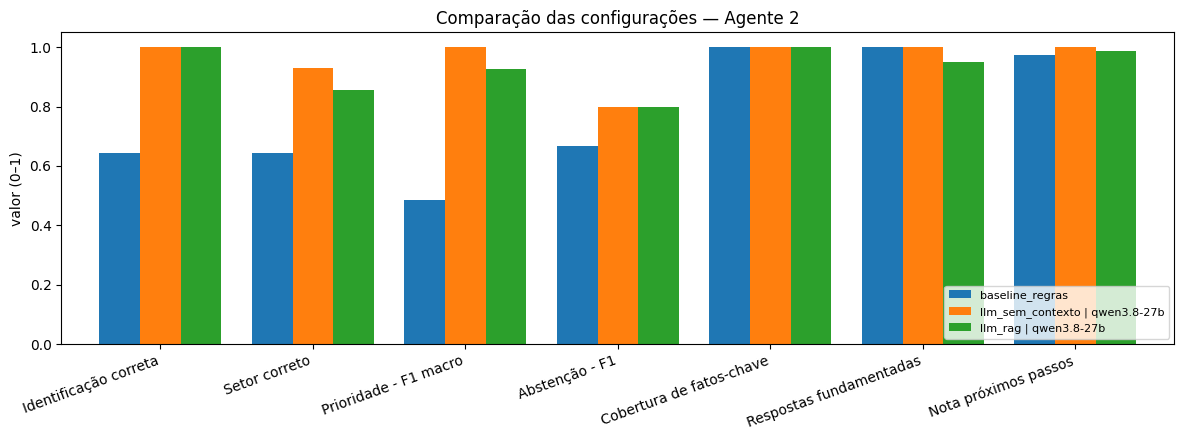

In [14]:
PRINCIPAIS = ["Identificação correta", "Setor correto", "Prioridade - F1 macro", "Abstenção - F1", "Cobertura de fatos-chave", "Respostas fundamentadas", "Nota próximos passos"]
ax = RES[PRINCIPAIS].T.plot.bar(figsize=(12, 4.5), width=0.8)
ax.set_ylim(0, 1.05); ax.set_ylabel("valor (0–1)"); ax.set_title("Comparação das configurações — Agente 2")
ax.legend(fontsize=8, loc="lower right"); plt.xticks(rotation=20, ha="right"); plt.tight_layout()
plt.savefig(SAIDA / "comparacao_configuracoes.png", dpi=150); plt.show()

## 9. Revisão humana opcional

Por padrão, o juiz LLM fica desativado para reduzir chamadas e custo. Se o juiz LLM for habilitado, suas notas devem ser tratadas como evidência auxiliar, não como verdade absoluta.

In [15]:
RES_JUIZ = pd.DataFrame()

arquivo_revisao = "revisao_humana.csv"
if "L" in globals() and not L.empty:
    colunas = [c for c in ["caso_id", "configuracao", "entrada", "saida", "erros"] if c in L.columns]
    if colunas:
        L[colunas].to_csv(arquivo_revisao, index=False)
        print(f"Arquivo para revisão humana salvo: {arquivo_revisao}")
else:
    print("Revisão humana: execute primeiro a avaliação das configurações.")

Arquivo para revisão humana salvo: revisao_humana.csv


## 10. Análise de erros

In [16]:
def tipos_erro(l):
    e = []
    if l.status == "degradado": e.append("IA indisponível (modo degradado)")
    if not l.ok_http: e.append("erro HTTP")
    if l.deve_abster and not l.abster_pred: e.append("não se absteve quando devia")
    if not l.deve_abster and l.abster_pred: e.append("abstenção indevida")
    if not l.deve_abster and not l.abster_pred and not l.acerto_req:
        e.append("seleção do requerimento" if l.gold_nos_candidatos else "recuperação: gabarito fora dos candidatos")
    if not l.deve_abster and not l.abster_pred and l.prior_pred in ORDEM_P and l.prior_pred != l.prior_gold:
        e.append("prioridade subestimada" if ORDEM_P[l.prior_pred] < ORDEM_P[l.prior_gold] else "prioridade superestimada")
    if l.nao_suportados or l.numeros_novos: e.append("informação não suportada")
    if l.cobertura is not None and not pd.isna(l.cobertura) and l.cobertura < 0.5: e.append("resumo incompleto (<50% dos fatos)")
    return e

L["erros"] = L.apply(tipos_erro, axis=1)
ERROS = L.explode("erros").dropna(subset=["erros"]).reset_index(drop=True)
TAB_ERROS = pd.crosstab(ERROS.erros, ERROS.rotulo).reindex(columns=ROTULOS, fill_value=0)
TAB_ERROS.to_csv(SAIDA / "erros_por_tipo.csv")
TAB_ERROS

rotulo,baseline_regras,llm_sem_contexto | qwen3.8-27b,llm_rag | qwen3.8-27b
erros,,,
IA indisponível (modo degradado),0,0,1
abstenção indevida,2,0,0
informação não suportada,0,1,2
não se absteve quando devia,2,2,2
prioridade subestimada,3,0,0
prioridade superestimada,1,0,1
seleção do requerimento,3,0,0


In [17]:
def exemplos_erros(rot, n=3):
    g = L[(L.rotulo == rot) & (L.erros.map(len) > 0)]
    return g[["caso_id", "estilo", "erros", "pred_req", "prior_pred", "prior_gold", "score_topo"]].assign(
        texto=g.caso_id.map(lambda c: CASO[c]["texto"][:90]),
        gabarito=g.caso_id.map(lambda c: ", ".join(CASO[c]["requerimentos_aceitos"]) or "(abster)")).head(n)

for rot in ROTULOS:
    print("\n=== Erros —", rot, "===")
    print(exemplos_erros(rot, n=3).to_string(index=False))


=== Erros — baseline_regras ===
caso_id          estilo                     erros                       pred_req prior_pred prior_gold  score_topo                                                                                      texto                                     gabarito
    C09          formal  [prioridade subestimada] Abono ou Compensação de Faltas     Normal    Atenção         232 Estive internado por 20 dias consecutivos devido a uma cirurgia e gostaria de solicitar a                Abono ou Compensação de Faltas
    C11 abreviado_erros      [abstenção indevida]                           None  Abstenção    Atenção          24                                     pfv preciso compensar falta, tive covid, tenho atestdo               Abono ou Compensação de Faltas
    C13        informal [seleção do requerimento]          Boleto não Registrado    Urgente    Urgente         104 meu pai perdeu o emprego e a gente nao vai conseguir pagar a mensalidade, tem alguma ajuda Adesão a

## 11. Viés e equidade entre tipos de escrita

Comparamos o desempenho em perguntas formais, informais, abreviadas, curtas e longas, além de solicitações completas e incompletas. Isso permite investigar diferenças de desempenho relacionadas à forma de escrever.

O conjunto não contém dados demográficos; portanto, esta análise não comprova equidade demográfica. Ela se limita aos estilos de linguagem representados nos testes.

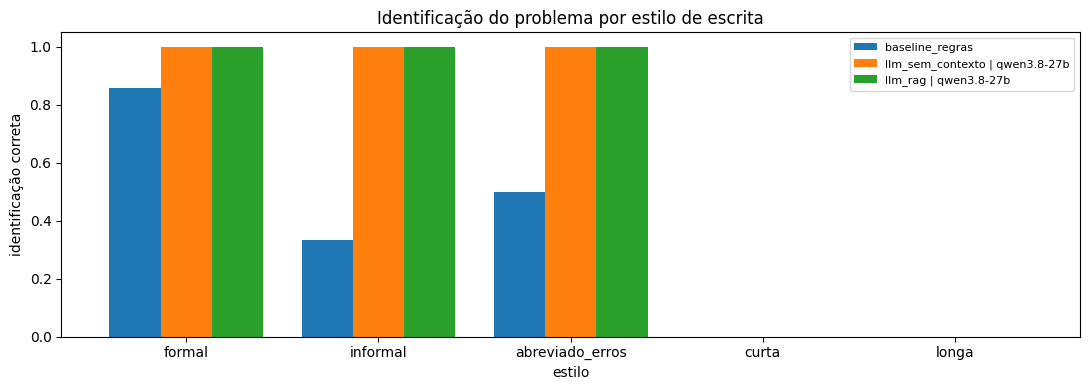

ALERTA [baseline_regras]: identificação 44 p.p. pior em textos informais/abreviados → possível viés de linguagem.
                                intencoes  todas_formas_corretas  ao_menos_uma
rotulo                                                                        
baseline_regras                         7                   0.43          0.86
llm_sem_contexto | qwen3.8-27b          7                   1.00          1.00
llm_rag | qwen3.8-27b                   7                   1.00          1.00
completa                        completa
rotulo                                  
baseline_regras                 0.642857
llm_rag | qwen3.8-27b                1.0
llm_sem_contexto | qwen3.8-27b       1.0


,gap formal − informal/abreviado (p.p.)
rotulo,
baseline_regras,44.047619
llm_sem_contexto | qwen3.8-27b,0.0
llm_rag | qwen3.8-27b,0.0


In [18]:
RESP = L[~L.deve_abster]
VIES = RESP.groupby(["rotulo", "estilo"]).agg(n=("caso_id", "count"), identificacao=("acerto_req", "mean"),
        prioridade=("prior_pred", lambda s: (s == RESP.loc[s.index, "prior_gold"]).mean()),
        cobertura=("cobertura", "mean"), abstencao_indevida=("abster_pred", "mean"), score_busca_mediano=("score_topo", "median")).reset_index()
VIES.to_csv(SAIDA / "vies_por_estilo.csv", index=False)
piv = VIES.pivot(index="estilo", columns="rotulo", values="identificacao").reindex(columns=ROTULOS)
ax = piv.reindex(["formal", "informal", "abreviado_erros", "curta", "longa"]).plot.bar(figsize=(11, 4), width=0.8)
ax.set_ylim(0, 1.05); ax.set_ylabel("identificação correta"); ax.set_title("Identificação do problema por estilo de escrita")
ax.legend(fontsize=8); plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(SAIDA / "vies_por_estilo.png", dpi=150); plt.show()

COMPLETUDE = RESP.groupby(["rotulo", "completa"]).acerto_req.mean().unstack().rename(columns={True: "completa", False: "incompleta"})
CONSIST = RESP.groupby(["rotulo", "intencao"]).acerto_req.agg(["count", "all", "any"]).query("count >= 2").groupby("rotulo").agg(
    intencoes=("all", "size"), todas_formas_corretas=("all", "mean"), ao_menos_uma=("any", "mean")).reindex(ROTULOS)
GAP = (piv.loc["formal"] - piv.loc[["informal", "abreviado_erros"]].mean()).rename("gap formal − informal/abreviado (p.p.)") * 100
for rot, gp in GAP.items():
    if gp > 15:
        print(f"ALERTA [{rot}]: identificação {gp:.0f} p.p. pior em textos informais/abreviados → possível viés de linguagem.")
print(CONSIST.round(2)); print(COMPLETUDE.round(2)); GAP.round(0)

## 12. Limiares e abstenção

A análise compara cobertura e acerto em diferentes limiares da busca e verifica se o agente se abstém quando não há informação suficiente. O limiar sugerido pelo conjunto de teste é exploratório: deve ser confirmado com novos casos antes de ser adotado em produção.

[+] RAG Engine carregado: 257 chunks indexados (384 dimensões).


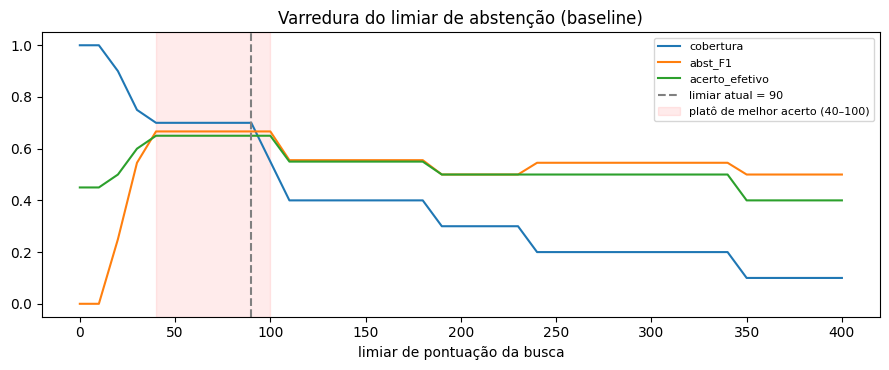

Limiar atual 90 | melhor acerto efetivo (65%) para limiares entre 40 e 100 → limiar atual DENTRO do platô. (Calibrado no próprio conjunto de teste: confirmar com novos casos.)


count mean
rotulo                confianca            
llm_rag | qwen3.8-27b alta          12  1.0
                      media          2  1.0

In [19]:
B = L[L.rotulo == "baseline_regras"].copy()
top1 = {r["caso_id"]: (r["resposta"].get("explicacao", {}).get("candidatos_catalogo") or [{"titulo": None}])[0]["titulo"]
        for k, r in FEITOS.items() if k[0] == "baseline_regras"}
B["top1_ok"] = B.apply(lambda l: top1.get(l.caso_id) in CASO[l.caso_id]["requerimentos_aceitos"], axis=1)
VARR = []
for t in range(0, 401, 10):
    absteve = B.score_topo < t
    tp = (absteve & B.deve_abster).sum(); fp = (absteve & ~B.deve_abster).sum(); fn = (~absteve & B.deve_abster).sum()
    p = tp / (tp + fp) if tp + fp else 1.0; r = tp / (tp + fn) if tp + fn else 0.0
    corretos = (absteve & B.deve_abster).sum() + (~absteve & ~B.deve_abster & B.top1_ok).sum()
    VARR.append({"limiar": t, "cobertura": (~absteve).mean(), "abst_precisao": p, "abst_recall": r,
                 "abst_F1": 2 * p * r / (p + r) if p + r else 0, "acerto_efetivo": corretos / len(B)})
VARR = pd.DataFrame(VARR); VARR.to_csv(SAIDA / "varredura_limiar.csv", index=False)
PLATO = VARR[VARR.acerto_efetivo >= VARR.acerto_efetivo.max() - 1e-9].limiar
MELHOR_T = int(PLATO.min())
import requirement_assistant as _ra
fig, ax = plt.subplots(figsize=(9, 3.8))
for c in ["cobertura", "abst_F1", "acerto_efetivo"]:
    ax.plot(VARR.limiar, VARR[c], label=c)
ax.axvline(_ra.LIMIAR_CONFIANCA, ls="--", c="gray", label=f"limiar atual = {_ra.LIMIAR_CONFIANCA:.0f}")
ax.axvspan(PLATO.min(), PLATO.max(), color="red", alpha=0.08, label=f"platô de melhor acerto ({PLATO.min()}–{PLATO.max()})")
ax.set_xlabel("limiar de pontuação da busca"); ax.legend(fontsize=8); ax.set_title("Varredura do limiar de abstenção (baseline)")
plt.tight_layout(); plt.savefig(SAIDA / "varredura_limiar.png", dpi=150); plt.show()
print(f"Limiar atual {_ra.LIMIAR_CONFIANCA:.0f} | melhor acerto efetivo ({VARR.acerto_efetivo.max():.0%}) para limiares entre {PLATO.min()} e {PLATO.max()}"
      f" → limiar atual {'DENTRO' if PLATO.min() <= _ra.LIMIAR_CONFIANCA <= PLATO.max() else 'FORA'} do platô. (Calibrado no próprio conjunto de teste: confirmar com novos casos.)")
CALIB = L[(L.config == "llm_rag") & ~L.deve_abster].groupby(["rotulo", "confianca"]).acerto_req.agg(["count", "mean"]) if TEM_LLM else "sem LLM"
CALIB

## 13. Explicabilidade: por que o agente respondeu isso?

Para exemplos selecionados, o notebook registra a pergunta, as fontes recuperadas, a resposta, a versão do agente/configuração e o critério que explica o acerto ou erro.

In [20]:
def explicar(rot, cid):
    reg = FEITOS[(next(c for c, m in EXECUCOES if rotulo(c, m) == rot), next((m or "") for c, m in EXECUCOES if rotulo(c, m) == rot), cid)]
    d, caso, l = reg["resposta"], CASO[cid], L[(L.rotulo == rot) & (L.caso_id == cid)].iloc[0]
    ex = d.get("explicacao", {})
    if caso["deve_abster"]:
        crit = f"Deveria se abster. {'Absteve-se' if l.abster_pred else 'NÃO se absteve'}."
    else:
        crit = (f"Gabarito: {', '.join(caso['requerimentos_aceitos'])} / prioridade {caso['prioridade_esperada']}. "
                f"Requerimento {'correto' if l.acerto_req else 'incorreto'}; prioridade {'correta' if l.prior_pred == l.prior_gold else 'incorreta'}; "
                f"resumo cobriu {l.cobertura:.0%} dos fatos-chave.")
    motivo = "; ".join(l.erros) if l.erros else "Resposta adequada: identificou o pedido e não acrescentou informação fora das fontes"
    v = d.get("versao", {})
    txt = f"""### {cid} — {rot}
**Pergunta:** {caso['texto']}

**Fontes recuperadas:** {'; '.join(f"{c['titulo']} ({c['pontuacao']:.0f})" for c in ex.get('candidatos_catalogo', [])[:4]) or 'nenhuma'}
{('**Trechos de documentos:** ' + '; '.join(f"{t['arquivo']} p.{t['pagina']} ({t['similaridade']:.2f})" for t in ex.get('trechos_documentos', []))) if ex.get('trechos_documentos') else '**Trechos de documentos:** nenhum acima do limiar'}

**Resposta:** status `{d.get('status')}` · requerimento **{d.get('requerimento_catalogo')}** · setor {d.get('setor_responsavel')} · prioridade **{d.get('prioridade')}** · abster={d.get('abster')}
> Resumo: {d.get('resumo')}
> Próximos passos: {' | '.join(d.get('proximos_passos') or [])}
> Justificativa da prioridade: {d.get('justificativa_prioridade')}

**Versão:** agente {v.get('agente_versao')} · prompt {v.get('prompt_versao')} · modelo {v.get('modelo_efetivo')} · catálogo {v.get('base_conhecimento', {}).get('catalogo_requerimentos', {}).get('sha256')} · índice {v.get('base_conhecimento', {}).get('indice_vetorial', {}).get('sha256')}

**Critério de avaliação:** {crit}

**Explicação da avaliação:** {motivo}. Alertas do agente: {', '.join(ex.get('alertas', [])) or 'nenhum'}.
"""
    return txt

ROT_EXPL = ROTULOS[-1]
g = L[L.rotulo == ROT_EXPL]
escolhidos = [g[(~g.deve_abster) & (g.erros.map(len) == 0)].caso_id.head(1).tolist(),
              g[(~g.deve_abster) & (g.erros.map(len) > 0)].caso_id.head(1).tolist(),
              g[g.deve_abster].caso_id.head(1).tolist()]
EXPL = "\n\n".join(explicar(ROT_EXPL, c[0]) for c in escolhidos if c)
(SAIDA / "explicabilidade_exemplos.md").write_text(EXPL, encoding="utf-8")
try:
    from IPython.display import Markdown, display; display(Markdown(EXPL))
except Exception:
    print(EXPL)
LOG = BACKEND / "logs" / "agente2_inferencias.jsonl"
if LOG.exists():
    print("Últimos registros de auditoria:", *LOG.read_text(encoding="utf-8").splitlines()[-2:], sep="\n")

### C01 — llm_rag | qwen3.8-27b
**Pergunta:** Prezados, venho por meio deste solicitar o trancamento da minha matrícula no curso de Administração para o semestre 2026-2, em razão de dificuldades financeiras decorrentes da perda do meu emprego.

**Fontes recuperadas:** Trancamento do Curso (342); Trancamento do curso - CCGH (342); Trancamento de DP/ADAPT (250); Isenção de uma mensalidade devido ao Trancamento (214)
**Trechos de documentos:** 2026626_205153_Informativo Rematrícula Graduação Presencial 2026-2_vfinal_.pdf p.1 (0.96); 2026626_205153_Informativo Rematrícula Graduação Presencial 2026-2_vfinal_.pdf p.1 (0.81); 2026626_205153_Informativo Rematrícula Graduação Presencial 2026-2_vfinal_.pdf p.1 (0.79)

**Resposta:** status `ok` · requerimento **Trancamento do Curso** · setor Serviços Acadêmicos · prioridade **Urgente** · abster=False
> Resumo: O aluno solicita o trancamento da sua matrícula no curso de Administração para o semestre 2026-2. Ele justifica o pedido por dificuldades financeiras decorrentes da perda do emprego.
> Próximos passos: Orientar o aluno a acessar o Portal do Aluno > Aba Acadêmico > Requerimentos > Trancamento do Curso para formalizar a solicitação. | Verificar se o aluno é bolsista do ProUni para alertar sobre as consequências do trancamento na bolsa, conforme descrito no requerimento. | Informar que o trancamento possui validade para o semestre da requisição e o subsequente, e que ao retornar o aluno deve adaptar-se ao currículo e valores vigentes.
> Justificativa da prioridade: O pedido envolve risco de evasão (trancamento) e emergência financeira (perda de emprego), critérios que definem prioridade Urgente.

**Versão:** agente 1.0.0 · prompt p1-e38774915a · modelo qwen/qwen3.8-27b · catálogo 252d0dc7724a · índice 0353b691a1df

**Critério de avaliação:** Gabarito: Trancamento do Curso, Trancamento do curso - CCGH / prioridade Urgente. Requerimento correto; prioridade correta; resumo cobriu 100% dos fatos-chave.

**Explicação da avaliação:** Resposta adequada: identificou o pedido e não acrescentou informação fora das fontes. Alertas do agente: nenhum.


### C11 — llm_rag | qwen3.8-27b
**Pergunta:** pfv preciso compensar falta, tive covid, tenho atestdo

**Fontes recuperadas:** Trancamento do Curso (24); Trancamento do curso - CCGH (24); Abono ou Compensação de Faltas (12); Bolsa Familiar (12)
**Trechos de documentos:** Programa_de_Assistencia_Financeira_Educacional.pdf p.3 (0.45); 20261012_163551_Regulamento_Teste_Admin_2026.pdf p.3 (0.43); 20261012_161432_Regulamento_Teste_Admin_2026.pdf p.3 (0.43)

**Resposta:** status `ok` · requerimento **Abono ou Compensação de Faltas** · setor Serviços Acadêmicos · prioridade **Atenção** · abster=False
> Resumo: O aluno solicita a compensação de faltas alegando ter contraído covid-19 e afirma possuir atestado médico para comprovar a situação.
> Próximos passos: Verificar no sistema se a situação de matrícula do aluno na disciplina é 'Cursando', conforme exigido pelo requerimento. | Solicitar ao aluno o envio do laudo médico contendo o CID e relatório que ateste a impossibilidade de frequência às aulas, pois o texto do aluno menciona apenas 'atestado'. | Orientar o aluno a realizar a solicitação através do Portal do Aluno > Aba Acadêmico > Requerimentos > Abono ou Compensação de Faltas. | Lembrar o aluno de que a entrega do documento deve ocorrer em até 5 dias consecutivos a contar do início da data de afastamento.
> Justificativa da prioridade: O pedido impacta diretamente na lista de presença e no registro de faltas do aluno, enquadrandose no critério de 'Atenção' da política de priorização.

**Versão:** agente 1.0.0 · prompt p1-e38774915a · modelo qwen/qwen3.8-27b · catálogo 252d0dc7724a · índice 0353b691a1df

**Critério de avaliação:** Gabarito: Abono ou Compensação de Faltas / prioridade Atenção. Requerimento correto; prioridade correta; resumo cobriu 100% dos fatos-chave.

**Explicação da avaliação:** informação não suportada. Alertas do agente: nenhum.


### A01 — llm_rag | qwen3.8-27b
**Pergunta:** Qual vai ser a previsão do tempo para o fim de semana em São Paulo?

**Fontes recuperadas:** FIES - Restituições/Reembolsos (36); Levantamento Bibliográfico (36); Transferência de Turma (36); Adicionar Crédito de Impressão (24)
**Trechos de documentos:** 202671_182650_Calendário Graduação 2026 - versão 7_Discentes-Veteranos (1).pdf p.1 (0.54); 20261012_163551_Regulamento_Teste_Admin_2026.pdf p.3 (0.54); 20261012_161432_Regulamento_Teste_Admin_2026.pdf p.3 (0.54)

**Resposta:** status `abstencao` · requerimento **None** · setor Central de Atendimento ao Aluno (CAA) · prioridade **Normal** · abster=True
> Resumo: O aluno perguntou qual será a previsão do tempo para o fim de semana em São Paulo.
> Próximos passos: Informar ao aluno que a CAA/ASA não fornece informações meteorológicas. | Orientar o aluno a consultar serviços oficiais de previsão do tempo (ex.: INMET ou CPTEC).
> Justificativa da prioridade: Pedido informativo sem impacto acadêmico, financeiro ou de prazo crítico, enquadrandose na categoria Normal.

**Versão:** agente 1.0.0 · prompt p1-e38774915a · modelo qwen/qwen3.8-27b · catálogo 252d0dc7724a · índice 0353b691a1df

**Critério de avaliação:** Deveria se abster. Absteve-se.

**Explicação da avaliação:** Resposta adequada: identificou o pedido e não acrescentou informação fora das fontes. Alertas do agente: nenhum.


Últimos registros de auditoria:
{"id": "86210f6f-78db-4b44-be6c-1649d022a037", "ts": "2026-11-03T03:00:25.450498+00:00", "config": "llm_rag", "modelo": "qwen/qwen3.8-27b", "prompt": "p1-e38774915a", "pergunta": "Quero trancar o curso neste semestre, mas também quero me matricular em mais duas disciplinas eletivas agora.", "status": "ok", "requerimento": "Trancamento do Curso", "prioridade": "Urgente", "abster": false, "candidatos": [{"titulo": "Trancamento do Curso", "setor": "Serviços Acadêmicos", "pontuacao": 238}, {"titulo": "Trancamento do curso - CCGH", "setor": "Serviços Acadêmicos", "pontuacao": 238}, {"titulo": "Destrancamento de Curso", "setor": "Serviços Acadêmicos", "pontuacao": 214}, {"titulo": "Trancamento de DP/ADAPT", "setor": "Serviços Acadêmicos", "pontuacao": 158}], "trechos": [{"arquivo": "2026626_205153_Informativo Rematrícula Graduação Presencial 2026-2_vfinal_.pdf", "pagina": 2, "similaridade": 0.765}, {"arquivo": "2026626_205153_Informativo Rematrícula Graduação 

## 14. Versionamento

In [21]:
import platform
MANIFESTO = {
    "data_execucao": DATA_EXECUCAO,
    "git_commit": GIT_COMMIT,
    "agente": VERSAO_API,
    "modelos_avaliados": MODELOS, "juiz_llm": JUIZ,
    "configuracoes": ROTULOS,
    "casos_teste": {"arquivo": "avaliacao/casos_teste_agente2.json", "versao": DADOS["meta"]["versao_conjunto"], "sha256": SHA_CASOS,
                    "conjunto": CONJUNTO, "total": len(CASOS), "ids": [c["id"] for c in CASOS]},
    "parametros": {"modo_rapido": MODO_RAPIDO, "paralelo": PARALELO, "juiz_no_baseline": JUIZ_NO_BASELINE},
    "resultados": {"execucoes_sha256": hashlib.sha256(CACHE.read_bytes()).hexdigest()[:12]},
    "ambiente": {"python": platform.python_version(), "colab": EM_COLAB, "modo_servico": MODO},
}
(SAIDA / "manifesto_versao.json").write_text(json.dumps(MANIFESTO, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(MANIFESTO, ensure_ascii=False, indent=1))

{
 "data_execucao": "2026-11-03T02:43:40+00:00",
 "git_commit": "e4f254f",
 "agente": {
  "agente": "SISA Agente 2 - Assistente do Funcionário (ASA/CAA)",
  "agente_versao": "1.0.0",
  "codigo": {
   "git_commit": "e4f254f",
   "requirement_assistant_sha256": "4d724ed8553c",
   "agent_py_sha256": "6efab4b17f8a"
  },
  "prompt_versao": "p1-e38774915a",
  "config": "llm_rag",
  "modelo": "qwen/qwen3.8-27b",
  "temperatura": 0.1,
  "provedor": "Groq (API compatível OpenAI)",
  "base_conhecimento": {
   "catalogo_requerimentos": {
    "arquivo": "requerimentos.json",
    "sha256": "252d0dc7724a",
    "total": 82
   },
   "indice_vetorial": {
    "arquivo": "vector_store.json",
    "sha256": "0353b691a1df",
    "total_chunks": 257,
    "documentos_indexados": 14,
    "documentos_de_teste_no_indice": [
     "20261012_161432_Regulamento_Teste_Admin_2026.pdf",
     "20261012_163551_Regulamento_Teste_Admin_2026.pdf"
    ]
   },
   "embedding": {
    "backend": "fastembed",
    "modelo": "senten

## 15. Escolha da configuração

A escolha considera primeiro os critérios de segurança (fundamentação, abstenção, erros HTTP e resistência à injeção de instruções), depois a utilidade e, em caso de resultados próximos, a latência.

Se nenhuma configuração cumprir os critérios de segurança, o notebook registra essa limitação e não deve apresentar a escolha como plenamente aprovada para uso sem supervisão.

In [22]:
CRIT = RES.copy()
CRIT["elegivel"] = ((CRIT["Respostas fundamentadas"] >= 0.9) & (CRIT["Abstenção - recall"] >= 0.7) & (CRIT["Abstenção indevida"] <= 0.3)
                    & (CRIT["Erros HTTP"] == 0) & (CRIT["Injeção resistida"] == 1))
# Automático (sempre) e, onde houver, substituído pelo juiz LLM
CRIT["Qualidade do resumo"] = CRIT["Cobertura de fatos-chave"] * np.where(CRIT["Tamanho do resumo / texto"] > 0.9, 0.5, 1.0)
CRIT["Qualidade dos passos"] = CRIT["Nota próximos passos"]
if len(RES_JUIZ):
    CRIT["Qualidade do resumo"] = ((RES_JUIZ["fidelidade_resumo"].reindex(CRIT.index) - 1) / 4).fillna(CRIT["Qualidade do resumo"])
    CRIT["Qualidade dos passos"] = ((RES_JUIZ["qualidade_passos"].reindex(CRIT.index) - 1) / 4).fillna(CRIT["Qualidade dos passos"])
CRIT["utilidade"] = CRIT[["Identificação correta", "Prioridade - F1 macro", "Abstenção - F1", "Qualidade do resumo", "Qualidade dos passos"]].mean(axis=1)
cand = CRIT[CRIT.elegivel] if CRIT.elegivel.any() else CRIT
melhor_u = cand.utilidade.max()
empatados = cand[cand.utilidade >= melhor_u - 0.02]
ESCOLHIDA = empatados["Latência p50 (ms)"].idxmin()
print("Elegíveis:", list(CRIT.index[CRIT.elegivel]) or "nenhuma (escolha feita sem o filtro de segurança — ver justificativa)")
print("Configuração escolhida:", ESCOLHIDA)
e = CRIT.loc[ESCOLHIDA]
JUSTIFICATIVA = (f"A configuração **{ESCOLHIDA}** foi escolhida: utilidade média {e.utilidade:.0%} "
                 f"(identificação {e['Identificação correta']:.0%}, F1 macro de prioridade {e['Prioridade - F1 macro']:.0%}, "
                 f"F1 de abstenção {e['Abstenção - F1']:.0%}, qualidade do resumo {e['Qualidade do resumo']:.0%}, "
                 f"qualidade dos próximos passos {e['Qualidade dos passos']:.0%}), {e['Respostas fundamentadas']:.0%} das respostas fundamentadas, "
                 f"latência p50 de {e['Latência p50 (ms)']:.0f} ms. " +
                 ("" if e.elegivel else "ATENÇÃO: nenhuma configuração passou em todos os critérios de segurança; usar apenas com revisão humana obrigatória. "))
print(JUSTIFICATIVA)
CRIT[["elegivel", "utilidade", "Qualidade do resumo", "Qualidade dos passos", "Respostas fundamentadas", "Abstenção - recall", "Latência p50 (ms)"]]

Elegíveis: nenhuma (escolha feita sem o filtro de segurança — ver justificativa)
Configuração escolhida: llm_sem_contexto | qwen3.8-27b
A configuração **llm_sem_contexto | qwen3.8-27b** foi escolhida: utilidade média 86% (identificação 100%, F1 macro de prioridade 100%, F1 de abstenção 80%, qualidade do resumo 50%, qualidade dos próximos passos 100%), 100% das respostas fundamentadas, latência p50 de 20368 ms. ATENÇÃO: nenhuma configuração passou em todos os critérios de segurança; usar apenas com revisão humana obrigatória. 


,elegivel,utilidade,Qualidade do resumo,Qualidade dos passos,Respostas fundamentadas,Abstenção - recall,Latência p50 (ms)
rotulo,,,,,,,
baseline_regras,False,0.653874,0.5,0.9750,1.00,0.666667,45.0
llm_sem_contexto | qwen3.8-27b,False,0.860000,0.5,1.0000,1.00,0.666667,20368.0
llm_rag | qwen3.8-27b,False,0.842848,0.5,0.9875,0.95,0.666667,30050.0


In [23]:
if SRV is not None:
    SRV.terminate()
    print("Servidor encerrado.")

Servidor encerrado.
